In [1]:

import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile

plt.rcParams["figure.figsize"] = (9, 3.5)

print("DSP Laboratory environment is ready!")


DSP Laboratory environment is ready!


## Task 1.1 – Generation of Elementary Discrete-Time Signals

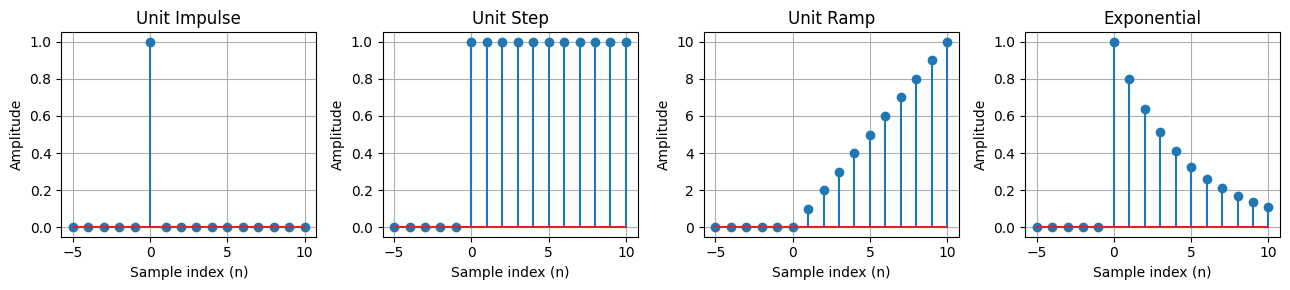

In [2]:

# Task 1.1: Generate elementary discrete-time signals

# Step 1: Create sample index from -5 to 10
n = np.arange(-5, 11)

# Step 2: Generate the four signals
delta = (n == 0).astype(float)   # Unit impulse
step = (n >= 0).astype(float)    # Unit step
ramp = n * step                  # Unit ramp
expo = (0.8**n) * step           # Exponential signal

# Step 3: Create four plots
fig, axes = plt.subplots(1, 4, figsize=(13, 3))

# Step 4: Display each signal
signals = [delta, step, ramp, expo]
titles = ["Unit Impulse", "Unit Step", "Unit Ramp", "Exponential"]

for ax, x, title in zip(axes, signals, titles):
    ax.stem(n, x)
    ax.set_title(title)
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

# Step 5: Display the graphs
plt.tight_layout()
plt.show()


## Task 1.2 – Change the Parameters


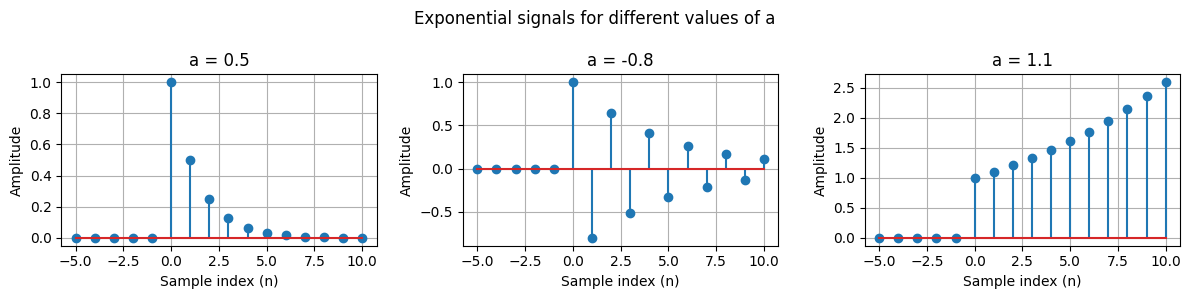

In [3]:

# Task 1.2 (Part A): Exponential signals

n = np.arange(-5, 11)
u = (n >= 0).astype(float)

# Three values of a
a_values = [0.5, -0.8, 1.1]

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for ax, a in zip(axes, a_values):
    x = (a**n) * u
    ax.stem(n, x)
    ax.set_title(f"a = {a}")
    ax.set_xlabel("Sample index (n)")
    ax.set_ylabel("Amplitude")
    ax.grid(True)

plt.suptitle("Exponential signals for different values of a")
plt.tight_layout()
plt.show()


### Part B: Comparison of Two Cosine Signals

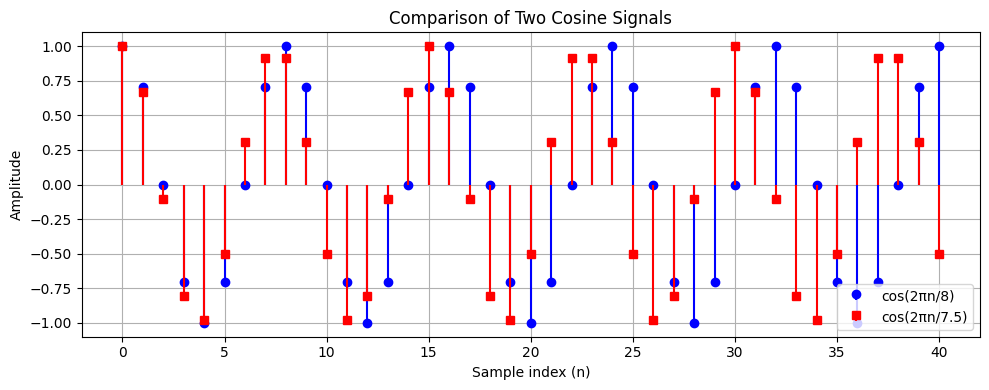

In [4]:

# Task 1.2 (Part B): Compare two cosine signals

# Sample index from 0 to 40
n = np.arange(0, 41)

# Generate the two cosine signals
x1 = np.cos(2 * np.pi * n / 8)
x2 = np.cos(2 * np.pi * n / 7.5)

# Plot both signals
plt.figure(figsize=(10, 4))

plt.stem(n, x1, linefmt='b-', markerfmt='bo',
         basefmt=' ', label='cos(2πn/8)')

plt.stem(n, x2, linefmt='r-', markerfmt='rs',
         basefmt=' ', label='cos(2πn/7.5)')

plt.title("Comparison of Two Cosine Signals")
plt.xlabel("Sample index (n)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()



Observation:

Both cosine signals are periodic in discrete time.

The first cosine signal, cos(2πn/8), repeats after every 8 samples.

The second cosine signal, cos(2πn/7.5), repeats after every 15 samples.

Therefore, both signals repeat exactly, but they have different fundamental periods.


In [10]:

# Task 1.3: Convert audio to WAV

import subprocess
import os

# Exact filename shown in Google Colab
input_file = "/content/Swaum_voice.m4a.mp4"

# Output WAV filename
output_file = "/content/Swaum_voice.wav"

# Convert audio to WAV (preserve original sampling rate)
subprocess.run([
    "ffmpeg",
    "-y",
    "-i", input_file,
    "-ac", "1",
    output_file
], check=True)

print("Audio conversion successful!")
print("Original file:", input_file)
print("Converted file:", output_file)


Audio conversion successful!
Original file: /content/Swaum_voice.m4a.mp4
Converted file: /content/Swaum_voice.wav


In [11]:

# Task 1.3: Read and analyse the audio recording

from scipy.io import wavfile
import numpy as np
import matplotlib.pyplot as plt

# Read the WAV file
fs, audio = wavfile.read("/content/Swaum_voice.wav")

# Convert audio to mono if it has multiple channels
if audio.ndim > 1:
    audio = audio.mean(axis=1)

# Convert samples to floating point for analysis
audio = audio.astype(float)

# Calculate duration
duration = len(audio) / fs

# Display recording information
print("AUDIO RECORDING INFORMATION")
print("---------------------------")
print("Sampling rate:", fs, "Hz")
print("Duration:", duration, "seconds")
print("Total number of samples:", len(audio))
print("Number of channels: 1 (Mono)")


AUDIO RECORDING INFORMATION
---------------------------
Sampling rate: 48000 Hz
Duration: 4.8213333333333335 seconds
Total number of samples: 231424
Number of channels: 1 (Mono)


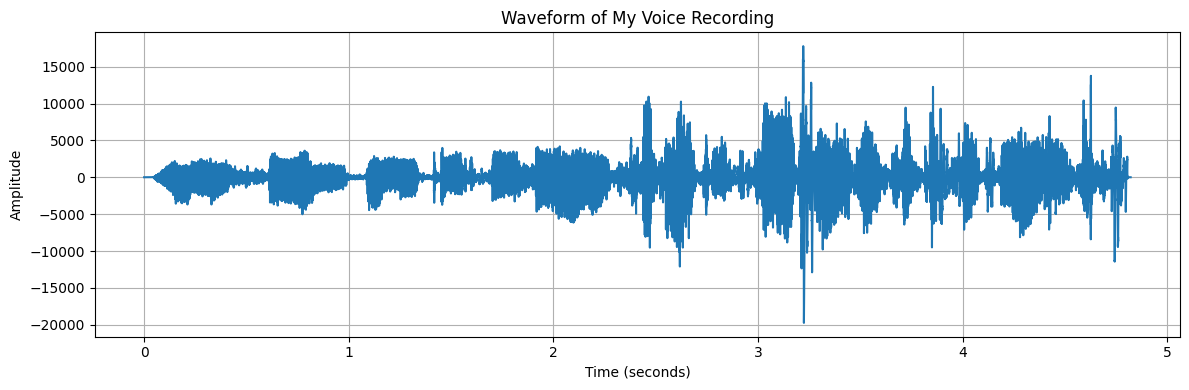

In [12]:

# Plot the recorded audio waveform

# Create time axis
time = np.arange(len(audio)) / fs

# Plot waveform
plt.figure(figsize=(12, 4))
plt.plot(time, audio)

plt.title("Waveform of My Voice Recording")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.grid(True)

plt.tight_layout()
plt.show()



## Analysis Questions

### Question 1: Sampling Rate

The sampling rate of my phone recording is 48,000 Hz (48 kHz). This means that 48,000 samples are recorded every second.

For one minute of mono audio:

N = 48,000 × 60

N = 2,880,000 samples.

Therefore, 2,880,000 numbers are required to store one minute of this recording.

### Question 2: Why is a stem plot more appropriate than a continuous line for x(n)?

A stem plot is more appropriate because a discrete-time signal is defined only at integer sample points. It shows individual samples clearly using vertical lines and markers. A continuous line may incorrectly suggest that the signal has values between sampling points.

### Question 3: What property would a growing exponential violate if it were an impulse response?

For a = 1.1, the exponential signal grows continuously. If this signal were an impulse response, it would violate the BIBO stability property. This is because a stable system must produce bounded output for every bounded input. The growing exponential is not absolutely summable, so the system would be unstable.


In [13]:
from IPython.display import Audio, display

display(Audio(audio, rate=fs))


# COU07506 – DIGITAL SIGNAL PROCESSING

## WEEK 1 – LAB 0: SETTING UP THE DSP LABORATORY

**Name:** Swaum Hussen Idd

**Registration Number:** 240242406676

**Module:** Digital Signal Processing

**Department:** Computer Studies Department

**Institution:** Dar es Salaam Institute of Technology

**Academic Year:** 2026/2027
